# Лабораторная работа №1: регрессия

**Задача:** по 11 физико-химическим характеристикам вина предсказать экспертную оценку `quality` (0–10).

**Данные:** [Wine Quality, UCI](https://archive.ics.uci.edu/dataset/186/wine+quality) — красные (1599) и белые (4898) вина. Используем весь датасет, поэтому вводим признак `is_red`.

**Метрики:** RMSE (основная, порог < 0.70) и MAE.

In [36]:
%pip install -q pandas numpy matplotlib seaborn "scikit-learn>=1.4"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.simplefilter("ignore")
%matplotlib inline
sns.set_theme(style="darkgrid")
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42

## 1. Знакомство с данными

### 1.1 Загрузка

Данные лежат в `data/` рядом с ноутбуком; если файлов нет, они скачиваются с UCI.

In [3]:
import os

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-{}.csv"


def load_wine(color):
    path = f"data/winequality-{color}.csv"
    return pd.read_csv(path if os.path.exists(path) else URL.format(color), sep=";")


red = load_wine("red")
white = load_wine("white")
red["is_red"] = 1
white["is_red"] = 0

df = pd.concat([red, white], ignore_index=True)
TARGET = "quality"
FEATURES = [c for c in df.columns if c != TARGET]

print(f"red: {red.shape}, white: {white.shape}, всего: {df.shape}")
print("Пропусков:", df.isna().sum().sum())
df.head()

red: (1599, 13), white: (4898, 13), всего: (6497, 13)
Пропусков: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


**Вывод.** 6497 объектов, 12 числовых признаков, пропусков нет — заполнение пропусков и кодирование категорий не нужны. Белых вин втрое больше, поэтому их закономерности будут доминировать.

### 1.2 Дубликаты

In [4]:
print(f"Полных дубликатов: {df.duplicated().sum()} ({df.duplicated().mean():.1%})")
print(f"Дубликатов по признакам (без quality): {df[FEATURES].duplicated().sum()}")
print(f"Одинаковые признаки, но разная quality: {(df.groupby(FEATURES)[TARGET].nunique() > 1).sum()}")

Полных дубликатов: 1177 (18.1%)
Дубликатов по признакам (без quality): 1177
Одинаковые признаки, но разная quality: 0


**Вывод.** 18% строк — точные копии, противоречивых нет. Если их оставить, копия может попасть и в train, и в test, и модель «узнает» уже виденный объект — тестовая метрика будет завышена. Удалим дубликаты до разбиения.

### 1.3 Целевая переменная

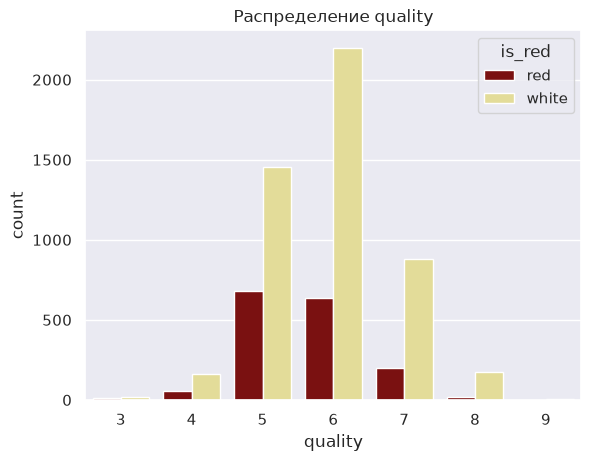

mean = 5.818, std = 0.873
{'white': 5.88, 'red': 5.64}


is_red,red,white,share
quality,,,
3,10,20,0.005
4,53,163,0.033
5,681,1457,0.329
6,638,2198,0.437
7,199,880,0.166
8,18,175,0.030
9,0,5,0.001


In [5]:
counts = pd.crosstab(df[TARGET], df["is_red"].map({0: "white", 1: "red"}))
counts["share"] = (counts.sum(axis=1) / len(df)).round(3)

sns.countplot(data=df, x=TARGET, hue=df["is_red"].map({0: "white", 1: "red"}),
              palette={"white": "khaki", "red": "darkred"})
plt.title("Распределение quality")
plt.show()

print(f"mean = {df[TARGET].mean():.3f}, std = {df[TARGET].std():.3f}")
print(df.groupby("is_red")[TARGET].mean().round(2).rename({0: "white", 1: "red"}).to_dict())
counts

**Вывод.**
- 76% вин имеют оценку 5 или 6; оценок 3 всего 30, оценок 9 — 5. Модель, минимизирующая квадратичную ошибку, будет тянуть прогноз к 5–6 и хуже предсказывать редкие оценки. Поэтому разбиение стратифицируем по `quality`.
- std(`quality`) ≈ 0.87 — примерно такая RMSE у константного прогноза (baseline). Порог 0.70 требует снизить её на ~20%.
- Красные вина в среднем оценены чуть ниже белых (5.64 против 5.88).

### 1.4 Распределения признаков

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


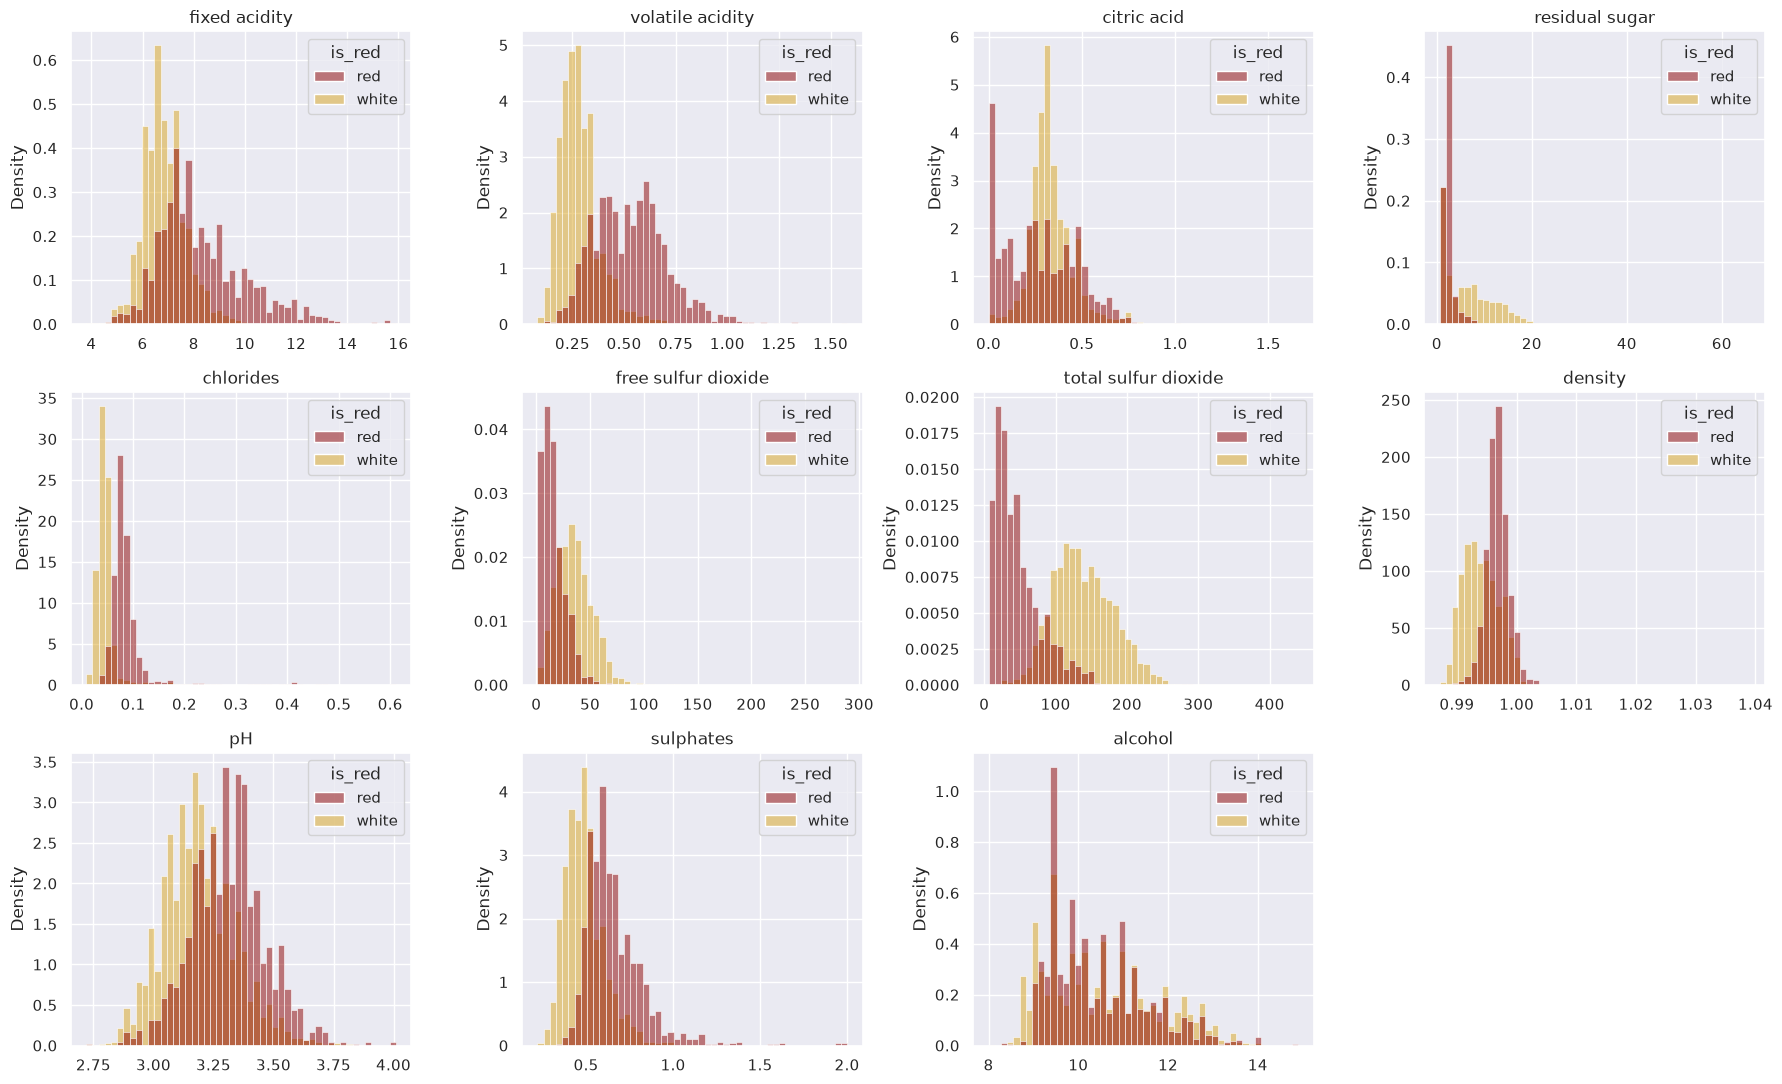

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), FEATURES[:-1]):
    sns.histplot(data=df, x=col, hue=df["is_red"].map({0: "white", 1: "red"}),
                 palette={"white": "goldenrod", "red": "darkred"},
                 stat="density", common_norm=False, bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [37]:
df.groupby(df["is_red"].map({0: "white", 1: "red"}))[FEATURES[:-1]].mean().T.round(3)

is_red,red,white
fixed acidity,8.320,6.855
volatile acidity,0.528,0.278
citric acid,0.271,0.334
residual sugar,2.539,6.391
chlorides,0.087,0.046
free sulfur dioxide,15.875,35.308
total sulfur dioxide,46.468,138.361
density,0.997,0.994
pH,3.311,3.188
sulphates,0.658,0.490


**Вывод.**
- **Масштабы различаются на порядки** (std у `density` 0.003, у `total sulfur dioxide` 57). Для интерпретации весов линейной регрессии нужна стандартизация; деревьям масштаб не важен — они сравнивают значение с порогом.
- **Длинные правые хвосты** (`chlorides`, `residual sugar`, `free sulfur dioxide`, `sulphates`) и единичные экстремумы (`residual sugar` = 65.8, `free sulfur dioxide` = 289). Значения физически согласованы (сладкое вино плотнее, свободный SO₂ ≤ общего) — это не ошибки, не удаляем. На веса линейной модели такие точки влияют сильно, на деревья — слабо. Заметим: вина с экстремальным `free sulfur dioxide` получили оценки 3–4.
- **Хвосты `volatile acidity`, `chlorides`, `sulphates`, `fixed acidity` образованы в основном красными винами**: у них вдвое больше летучих кислот и хлоридов и втрое меньше общего SO₂. Красные и белые различаются по химии, поэтому одно и то же значение признака может значить разное для разных типов.

### 1.5 Связь признаков с `quality`

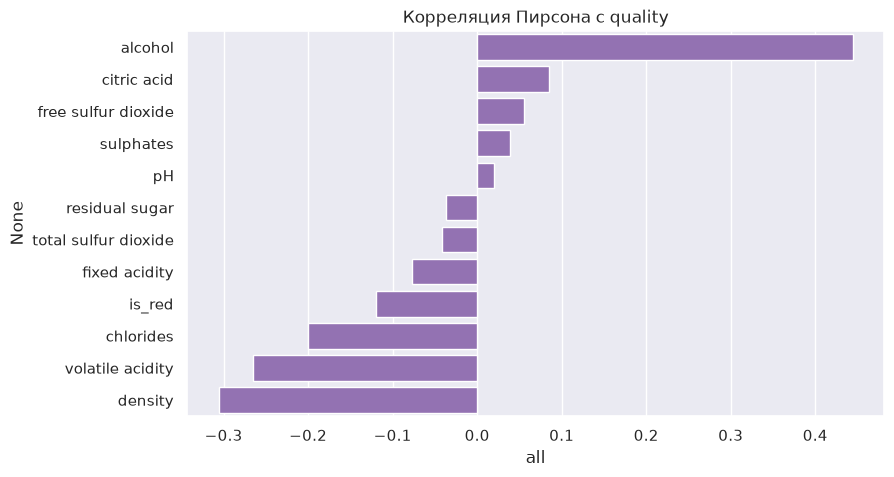

,all,red,white
alcohol,0.444,0.476,0.436
density,-0.306,-0.175,-0.307
volatile acidity,-0.266,-0.391,-0.195
chlorides,-0.201,-0.129,-0.210
is_red,-0.119,NaN,NaN
citric acid,0.086,0.226,-0.009
fixed acidity,-0.077,0.124,-0.114
free sulfur dioxide,0.055,-0.051,0.008
total sulfur dioxide,-0.041,-0.185,-0.175
sulphates,0.038,0.251,0.054


In [38]:
corr_target = pd.DataFrame({
    "all": df[FEATURES].corrwith(df[TARGET]),
    "red": red[FEATURES[:-1]].corrwith(red[TARGET]),
    "white": white[FEATURES[:-1]].corrwith(white[TARGET]),
}).sort_values("all", key=abs, ascending=False)

correlations = corr_target["all"].sort_values(ascending=False)
plot = sns.barplot(y=correlations.index, x=correlations, color="tab:purple")
plot.set_title("Корреляция Пирсона с quality")
plot.figure.set_size_inches(9, 5)
plt.show()

corr_target.round(3)

**Вывод.**
- **`alcohol` — самый сильный признак** (r ≈ 0.44 и у красных, и у белых): крепкие вина — из более спелого винограда, их оценивают выше. Ожидаем его на первом месте у всех моделей.
- **`volatile acidity`** («уксусная» кислотность, дефект вина) связана отрицательно, сильнее у красных (−0.39 против −0.20).
- **`density`** (−0.31) связана с качеством во многом через `alcohol` (см. 1.7).
- **`citric acid` и `sulphates` связаны с качеством только у красных** (0.23, 0.25); в общих данных эффект размывается до ~0. Низкая общая корреляция ≠ бесполезный признак: линейная модель такой эффект не уловит, деревья — могут.
- Максимальная корреляция всего 0.44, а оценка эксперта субъективна — RMSE, близкой к нулю, ждать не стоит.

### 1.6 Линейность связи

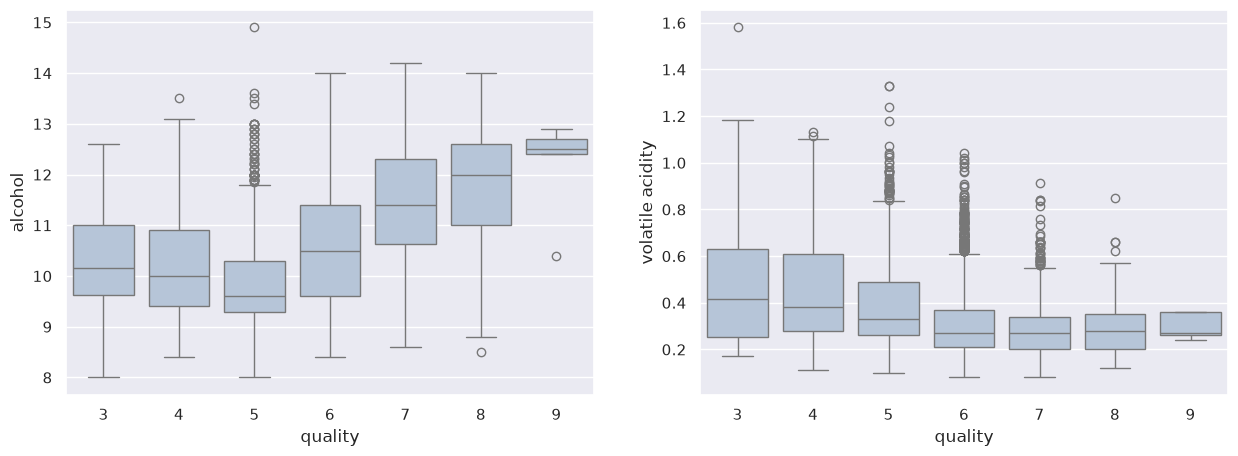

quality,3,4,5,6,7,8,9
alcohol,10.15,10.00,9.60,10.50,11.40,12.00,12.50
volatile acidity,0.42,0.38,0.33,0.27,0.27,0.28,0.27


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x=TARGET, y="alcohol", ax=axes[0], color="lightsteelblue")
sns.boxplot(data=df, x=TARGET, y="volatile acidity", ax=axes[1], color="lightsteelblue")
plt.show()

df.groupby(TARGET)[["alcohol", "volatile acidity"]].median().T.round(2)

**Вывод.** С оценки 5 медиана `alcohol` растёт монотонно (9.6 → 12.5), но у оценок 3–4 она выше, чем у 5: низкое качество определяется другими факторами, например высокой `volatile acidity`. Линейная модель описывает признак одним коэффициентом и такого не учтёт — от деревьев ждём лучшего качества.

### 1.7 Связи между признаками

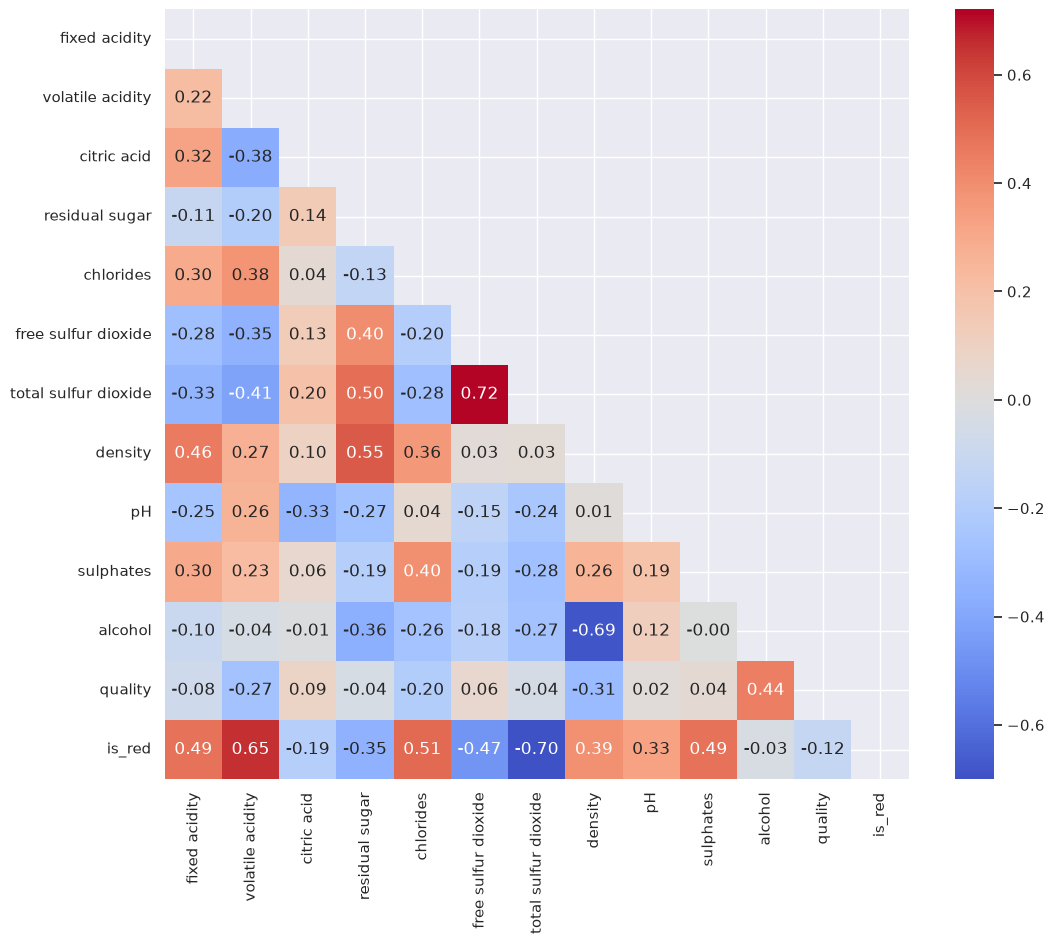

In [13]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            mask=np.triu(np.ones_like(corr, dtype=bool)), ax=ax)
plt.show()

**Вывод.**
- **`density` почти определяется `alcohol` (−0.69) и `residual sugar` (+0.55)**: спирт легче воды, сахар тяжелее. Плотность несёт мало новой информации, а веса коррелированных признаков в линейной модели могут компенсировать друг друга — интерпретировать их по отдельности надо осторожно. В деревьях такие признаки делят важность.
- `free` и `total sulfur dioxide` связаны (0.72): свободный SO₂ — часть общего.
- `is_red` сильно связан с `total sulfur dioxide` (−0.70) и `volatile acidity` (0.65): тип вина восстанавливается по химии, отдельный вклад `is_red` может быть мал.

### 1.8 Итоги EDA

| Наблюдение | Следствие для моделирования |
|---|---|
| 18% дубликатов | Удалить до разбиения |
| 76% оценок — 5 и 6 | Стратифицировать разбиение; ждать больших ошибок на редких оценках |
| std(`quality`) ≈ 0.87 | RMSE baseline ≈ 0.87 |
| Главные признаки: `alcohol`, `density`, `volatile acidity` | Ожидаем их наверху важности у всех моделей |
| Связи нелинейны и зависят от типа вина | Деревья должны превзойти линейную регрессию |
| Разные масштабы | Стандартизация для линейной регрессии |
| `density` ≈ f(`alcohol`, `residual sugar`) | Осторожно с интерпретацией весов |

## 2. Подготовка выборок

In [11]:
from sklearn.model_selection import train_test_split

data = df.drop_duplicates().reset_index(drop=True)
print(f"После удаления дубликатов: {len(data)} (удалено {len(df) - len(data)})")

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"train: {X_train.shape}, test: {X_test.shape}")

split_check = pd.DataFrame({
    "train, шт": y_train.value_counts().sort_index(),
    "test, шт": y_test.value_counts().sort_index(),
    "train, доля": y_train.value_counts(normalize=True).sort_index().round(3),
    "test, доля": y_test.value_counts(normalize=True).sort_index().round(3),
})
split_check.loc["is_red"] = [X_train["is_red"].sum(), X_test["is_red"].sum(),
                             round(X_train["is_red"].mean(), 3), round(X_test["is_red"].mean(), 3)]
split_check

После удаления дубликатов: 5320 (удалено 1177)
train: (4256, 12), test: (1064, 12)


,"train, шт","test, шт","train, доля","test, доля"
quality,,,,
3,24.0,6.0,0.006,0.006
4,165.0,41.0,0.039,0.039
5,1402.0,350.0,0.329,0.329
6,1858.0,465.0,0.437,0.437
7,685.0,171.0,0.161,0.161
8,118.0,30.0,0.028,0.028
9,4.0,1.0,0.001,0.001
is_red,1092.0,267.0,0.257,0.251


In [12]:
CV = 5

**Схема.** Тест используем один раз — для итоговой таблицы. Гиперпараметры и модели выбираем по кросс-валидации на train с 5 фолдами (`CV = 5`): модель 5 раз обучается на 4/5 train и проверяется на оставшейся части. `X_train` уже перемешан `train_test_split`, поэтому фолды случайные.

**Размер выборок.** 5320 объектов → **train 4256 (80%), test 1064 (20%)**. Train должно хватать на редкие оценки (24 вина с оценкой 3, 118 — с 8), а тест должен быть достаточно большим для устойчивой оценки. Параметры подбираем на CV, поэтому отдельная валидационная выборка не нужна и 20% хватает.

**Способ разбиения.**
- Случайный: в исходных данных сначала идут все красные, потом все белые.
- Со стратификацией по `quality`: классы несбалансированы, и без неё доли редких оценок в тесте «гуляли» бы, меняя сложность теста. Сейчас доли в train и test совпадают (таблица выше), доля красных тоже (~25%).
- Дубликаты удалены до разбиения — утечки нет. `random_state` зафиксирован — эксперимент воспроизводим.

**Почему нельзя многократно оценивать модели на одном тесте.** Выбирая по тесту лучшую из многих моделей, мы выбираем и ту, которой случайно повезло на этих 1064 объектах. Тест превращается в валидацию, модель подгоняется под него, итоговая оценка получается завышенной: на новых данных (скрытой выборке) качество будет хуже, а шум можно принять за улучшение.

## 3. Метрики

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat y_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat y_i)^2}$$

- **MAE** — средняя ошибка в баллах: MAE = 0.5 значит «в среднем промахиваемся на полбалла». Все ошибки входят линейно, интерпретировать проще всего.
- **RMSE** — типичный размер ошибки с большим весом крупных промахов, в тех же единицах, что `quality`. У константного прогноза средним равна std(`quality`).
- **Почему RMSE сильнее реагирует на большие ошибки:** ошибки возводятся в квадрат до усреднения. Ошибка 3 балла в MAE весит как 6 ошибок по 0.5, а в квадрате (9 против 0.25) — как 36.
- **Почему MAE и RMSE могут заметно различаться:** всегда MAE ≤ RMSE, равенство — только если все ошибки одинаковы по модулю. Чем больше доля редких крупных промахов (у нас — на оценках 3 и 8), тем больше RMSE превышает MAE.

В таблицу результатов записываем RMSE на train (для контроля разрыва train/test), RMSE и MAE на test.

In [13]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

results = {}


def add_result(name, y_train_pred, y_test_pred):
    results[name] = {
        "RMSE train": root_mean_squared_error(y_train, y_train_pred),
        "RMSE test": root_mean_squared_error(y_test, y_test_pred),
        "MAE test": mean_absolute_error(y_test, y_test_pred),
    }
    return pd.DataFrame(results).T.round(4)

## 4. Baseline

Константа выбирается под метрику: $\frac{1}{n}\sum (y_i - c)^2$ минимальна при $c = \bar y$ (производная $-\frac{2}{n}\sum (y_i - c) = 0$), а $\frac{1}{n}\sum |y_i - c|$ — при $c$ = медиана. Основная метрика RMSE, поэтому **baseline = среднее `quality` по train**.

In [14]:
best_constant = y_train.mean()
print(f"Константа: {best_constant:.4f}")

y_pred_baseline = best_constant * np.ones(y_test.shape)
add_result("Baseline", best_constant * np.ones(y_train.shape), y_pred_baseline)

Константа: 5.7953


,RMSE train,RMSE test,MAE test
Baseline,0.8796,0.8801,0.6948


In [15]:
y_pred_median = y_train.median() * np.ones(y_test.shape)
pd.DataFrame({
    "RMSE": [root_mean_squared_error(y_test, y_pred_baseline), root_mean_squared_error(y_test, y_pred_median)],
    "MAE": [mean_absolute_error(y_test, y_pred_baseline), mean_absolute_error(y_test, y_pred_median)],
}, index=[f"среднее ({y_train.mean():.2f})", f"медиана ({y_train.median():.0f})"]).round(4)

,RMSE,MAE
среднее (5.80),0.8801,0.6948
медиана (6),0.9032,0.6429


**Вывод.** Baseline (5.80): **RMSE 0.880, MAE 0.695** — это весь разброс `quality`, признаки не используются. Медиана лучше по MAE (0.643), но хуже по RMSE (0.903): каждая константа оптимальна для своей метрики. Модель полезна, только если её RMSE заметно ниже 0.880.

## 5. Модели

### 5.1 Линейная регрессия

$a(x) = \langle w, x \rangle + w_0$, веса минимизируют MSE на train. `Pipeline` выполняет `StandardScaler` → `LinearRegression`: scaler обучается только на train (и на каждом обучающем фолде при CV), утечки нет.

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

lin_reg = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression()),
]).fit(X_train, y_train)

y_pred_lr = lin_reg.predict(X_test)

cv_scores = cross_val_score(lin_reg, X_train, y_train, cv=CV, scoring="neg_root_mean_squared_error")
print("Mean CV RMSE = %.4f" % np.mean(-cv_scores))

add_result("Linear Regression", lin_reg.predict(X_train), y_pred_lr)

Mean CV RMSE = 0.7344


,RMSE train,RMSE test,MAE test
Baseline,0.8796,0.8801,0.6948
Linear Regression,0.7307,0.7292,0.5660


**Вывод.** Линейная регрессия лучше baseline (RMSE 0.880 → 0.729), то есть признаки информативны, но **порог 0.70 не пройден**. RMSE на train, CV и test почти равны (0.731 / 0.734 / 0.729): модель не переобучена, а **недообучена** — сумма линейных вкладов не описывает нелинейности и взаимодействия из EDA.

#### 5.1.1 Коэффициенты и масштабирование

Сравним веса модели на исходных и на стандартизованных признаках; справа — масштаб (std) признака.

Макс. разница предсказаний с масштабированием и без: 4.3520742565306136e-14


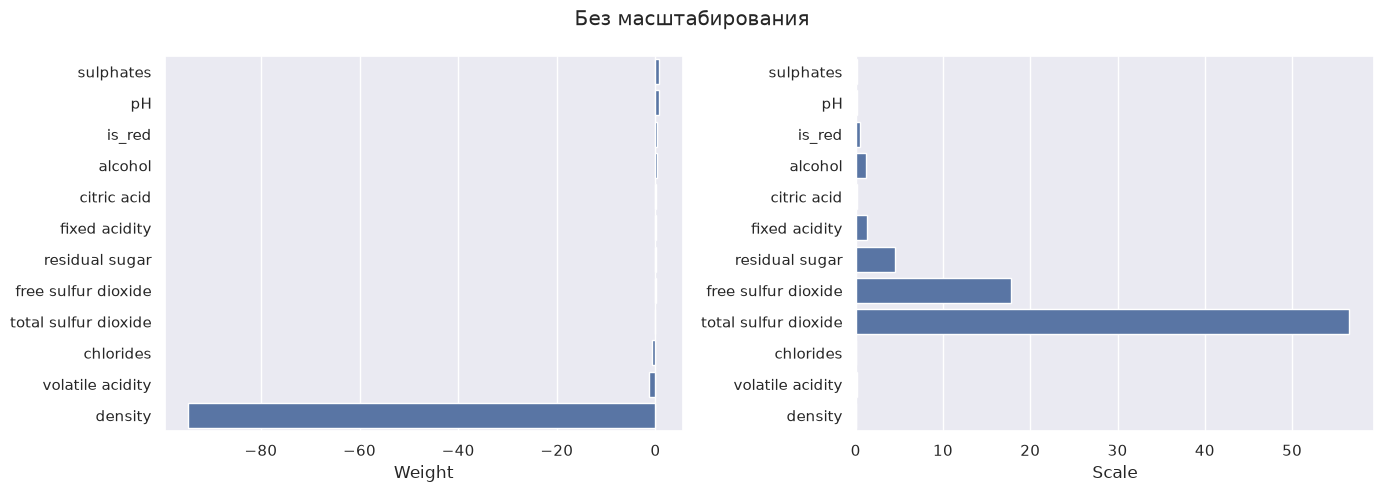

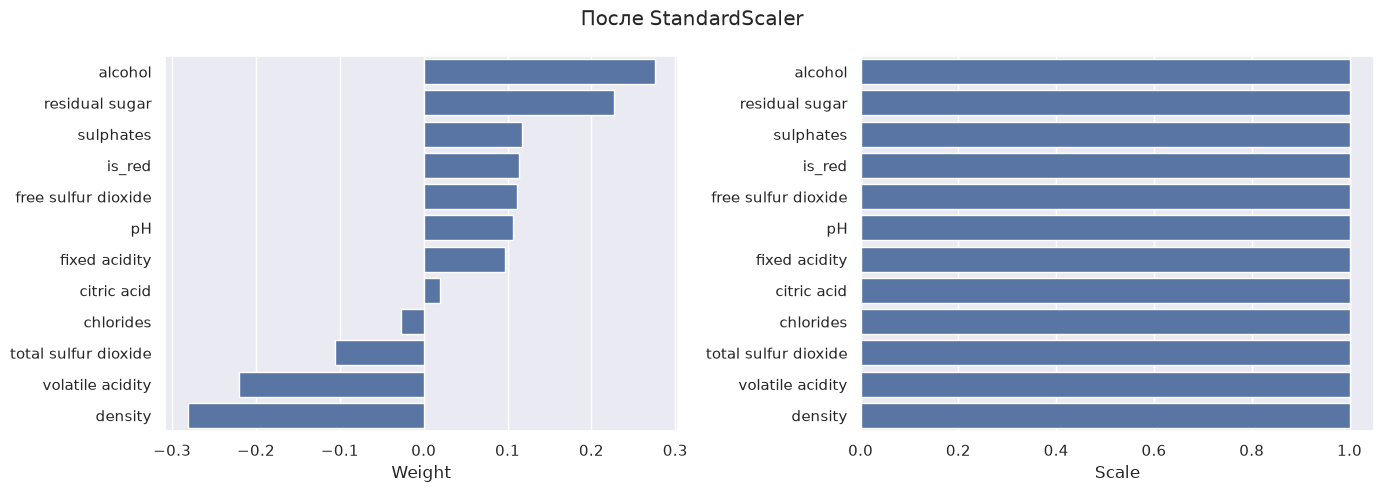

In [17]:
def show_weights(features, weights, scales, title):
    fig, axs = plt.subplots(figsize=(14, 5), ncols=2)
    sorted_weights = sorted(zip(weights, features, scales), reverse=True)
    weights = [x[0] for x in sorted_weights]
    features = [x[1] for x in sorted_weights]
    scales = [x[2] for x in sorted_weights]
    sns.barplot(y=features, x=weights, ax=axs[0])
    axs[0].set_xlabel("Weight")
    sns.barplot(y=features, x=scales, ax=axs[1])
    axs[1].set_xlabel("Scale")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


lin_reg_raw = LinearRegression().fit(X_train, y_train)
print("Макс. разница предсказаний с масштабированием и без:",
      np.abs(lin_reg_raw.predict(X_test) - y_pred_lr).max())

show_weights(FEATURES, lin_reg_raw.coef_, X_train.std(), "Без масштабирования")

X_train_scaled = lin_reg.named_steps["scaling"].transform(X_train)
show_weights(FEATURES, lin_reg.named_steps["regression"].coef_,
             pd.Series(X_train_scaled.std(axis=0), index=FEATURES), "После StandardScaler")

In [18]:
coefs = pd.DataFrame({
    "вес (исходные)": lin_reg_raw.coef_,
    "std признака": X_train.std().values,
    "вес (стандартизованные)": lin_reg.named_steps["regression"].coef_,
}, index=FEATURES)
coefs.sort_values("вес (стандартизованные)", key=abs, ascending=False).round(4)

,вес (исходные),std признака,вес (стандартизованные)
density,-94.7183,0.0030,-0.2810
alcohol,0.2314,1.1907,0.2755
residual sugar,0.0510,4.4500,0.2268
volatile acidity,-1.3258,0.1666,-0.2209
sulphates,0.8040,0.1461,0.1174
is_red,0.2604,0.4368,0.1137
free sulfur dioxide,0.0063,17.8237,0.1118
pH,0.6656,0.1603,0.1067
total sulfur dioxide,-0.0019,56.5538,-0.1054
fixed acidity,0.0731,1.3315,0.0973


**Нужно ли масштабирование?**
- **Для прогноза — нет**: `LinearRegression` без регуляризации даёт те же предсказания (разница ~1e-14), веса просто пересчитываются.
- **Для интерпретации — да.** Исходный вес — эффект роста признака на 1 единицу, а единицы несопоставимы. У `density` вес −94.7, но её std = 0.003, и рост на 1 г/см³ невозможен: большой вес — следствие маленького масштаба. У `total sulfur dioxide` вес −0.002 при std = 56.6. После стандартизации вес — эффект роста на 1 std при прочих равных: `density` −0.28, `total sulfur dioxide` −0.11, а `chlorides` (исходный вес −0.75) почти не влияет (−0.03).

**Наиболее влиятельные признаки:** `density` (−0.28), `alcohol` (+0.28), `residual sugar` (+0.23), `volatile acidity` (−0.22). `alcohol` и `volatile acidity` совпадают с EDA. Но у `residual sugar` большой положительный вес при корреляции с `quality` около нуля — проверим, не эффект ли это корреляции признаков.

In [19]:
features_no_density = [c for c in FEATURES if c != "density"]
lin_reg_no_density = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression()),
]).fit(X_train[features_no_density], y_train)

cv_no_density = cross_val_score(lin_reg_no_density, X_train[features_no_density], y_train,
                                cv=CV, scoring="neg_root_mean_squared_error")
print("Mean CV RMSE без density = %.4f" % np.mean(-cv_no_density))

pd.DataFrame({
    "все признаки": coefs["вес (стандартизованные)"],
    "без density": pd.Series(lin_reg_no_density.named_steps["regression"].coef_, index=features_no_density),
    "corr с quality": X_train.corrwith(y_train),
}).sort_values("все признаки", key=abs, ascending=False).round(3)

Mean CV RMSE без density = 0.7364


,все признаки,без density,corr с quality
density,-0.281,NaN,-0.328
alcohol,0.276,0.398,0.469
residual sugar,0.227,0.065,-0.065
volatile acidity,-0.221,-0.233,-0.256
sulphates,0.117,0.099,0.045
is_red,0.114,0.027,-0.112
free sulfur dioxide,0.112,0.123,0.049
pH,0.107,0.048,0.051
total sulfur dioxide,-0.105,-0.123,-0.061
fixed acidity,0.097,-0.007,-0.080


**Вывод.** Без `density` веса перестраиваются: `alcohol` 0.28 → 0.40, `residual sugar` 0.23 → 0.07, `is_red` 0.11 → 0.03, а качество почти не меняется (CV RMSE 0.734 → 0.736). Вес — эффект «при прочих равных»: при фиксированной плотности больше сахара возможно только при большем спирте, поэтому `density`, `residual sugar` и `alcohol` компенсируют друг друга. **Надёжны выводы только про `alcohol` (+) и `volatile acidity` (−)**: их веса устойчивы и совпадают с EDA; остальные веса зависят от набора признаков.

### 5.2 Random Forest Regressor

Лес усредняет много глубоких деревьев; каждое обучается на бутстрэп-выборке и в каждом разбиении выбирает из случайной доли признаков (`max_features`). Деревья получаются разными, и усреднение снижает разброс их ошибок. Масштабирование не нужно.

По CV на train подбираем `max_features` (меньше — деревья разнообразнее) и `min_samples_leaf` (больше — деревья проще). `n_estimators = 300`: больше деревьев не переобучает, только стабилизирует результат.

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf_searcher = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    [{"max_features": [0.33, 0.5, 1.0], "min_samples_leaf": [1, 2, 5]}],
    scoring="neg_root_mean_squared_error", cv=CV,
)
rf_searcher.fit(X_train, y_train)
print("Best params:", rf_searcher.best_params_)
print("Best CV RMSE = %.4f" % -rf_searcher.best_score_)

pd.DataFrame(rf_searcher.cv_results_).pivot(
    index="param_min_samples_leaf", columns="param_max_features", values="mean_test_score"
).mul(-1).round(4)

Best params: {'max_features': 0.33, 'min_samples_leaf': 1}
Best CV RMSE = 0.6863


param_max_features,0.33,0.50,1.00
param_min_samples_leaf,,,
1,0.6863,0.6886,0.6933
2,0.6890,0.6888,0.6930
5,0.6946,0.6935,0.6964


In [21]:
rf = rf_searcher.best_estimator_
y_pred_rf = rf.predict(X_test)
add_result("Random Forest", rf.predict(X_train), y_pred_rf)

,RMSE train,RMSE test,MAE test
Baseline,0.8796,0.8801,0.6948
Linear Regression,0.7307,0.7292,0.5660
Random Forest,0.2521,0.6798,0.5256


**Вывод.**
- Лучшие параметры: `max_features = 0.33`, `min_samples_leaf = 1`; по сетке CV RMSE меняется слабо (0.686–0.696).
- **RMSE 0.680, MAE 0.526 — порог пройден**, лучше линейной регрессии (0.729). Деревья выражают правила вида «низкий `alcohol` **и** высокая `volatile acidity` → низкая оценка» — нелинейности и взаимодействия, которых нет у линейной модели.
- Разрыв train/test (0.25 против 0.68) для леса нормален: глубокие деревья запоминают train, а усреднение компенсирует их переобучение. Судим по CV (0.686) и тесту — они близки.

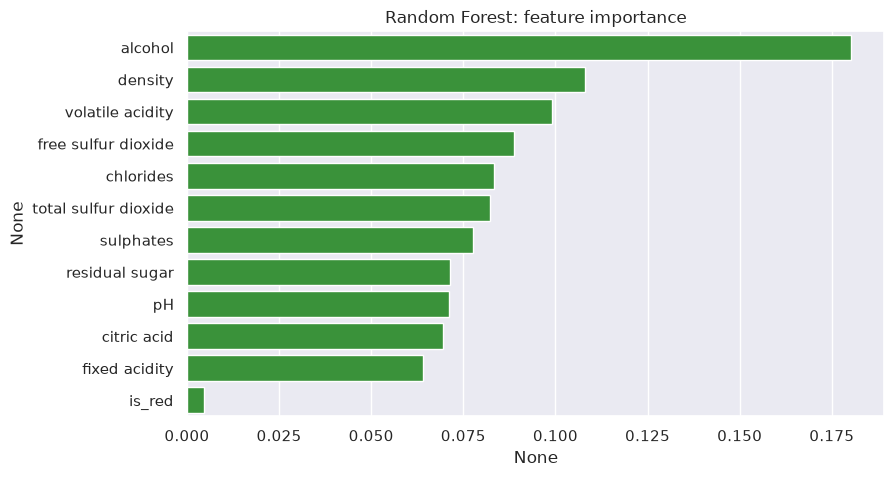

,alcohol,density,volatile acidity,free sulfur dioxide,chlorides,total sulfur dioxide,sulphates,residual sugar,pH,citric acid,fixed acidity,is_red
importance,0.18,0.108,0.099,0.089,0.083,0.082,0.078,0.071,0.071,0.069,0.064,0.005


In [22]:
rf_importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(y=rf_importance.index, x=rf_importance, ax=ax, color="tab:green")
ax.set_title("Random Forest: feature importance")
plt.show()
rf_importance.round(3).to_frame("importance").T

`feature_importances_` — суммарное уменьшение MSE в разбиениях по признаку, нормированное на 1.

**Вывод.**
- **`alcohol` (0.18)** — первый с двукратным отрывом, затем **`density` и `volatile acidity`** (~0.10) — как в EDA и линейной регрессии. Остальные 0.06–0.09: лес использует все признаки понемногу.
- Отличия от линейной регрессии: `residual sugar` у леса в нижней половине (его вес в LR был следствием компенсации с `density`); `chlorides` и `citric acid`, почти нулевые в LR, у леса получают обычную важность — их эффект нелинейный или есть только у одного типа вина.
- `is_red` ≈ 0: тип вина лес «узнаёт» по `total sulfur dioxide`, `volatile acidity`, `chlorides`.

### 5.3 Gradient Boosting Regressor

Бустинг строит деревья **последовательно**: каждое следующее предсказывает ошибки текущего ансамбля и добавляется с шагом `learning_rate`. Лес уменьшает разброс усреднением, бустинг — смещение, исправляя ошибки.

По CV на train подбираем при 500 деревьях:
- `learning_rate` — шаг: меньший шаг требует больше деревьев, большой шаг с большим числом деревьев переобучается;
- `max_depth` — глубина дерева: насколько сложные взаимодействия признаков оно может учесть;
- `min_samples_leaf` (3–7) — минимум объектов в листе: защищает от подгонки под единичные вина;
- `subsample` (0.6 или 1.0) — доля train, на которой обучается каждое дерево: при 0.6 каждое дерево видит случайные 60% объектов, деревья получаются разнообразнее и меньше подгоняются под шум.

In [24]:
from sklearn.ensemble import GradientBoostingRegressor

gb_searcher = GridSearchCV(
    GradientBoostingRegressor(n_estimators=500, random_state=RANDOM_STATE),
    [{"learning_rate": [0.01, 0.05, 0.1], "max_depth": [4, 6, 8],
      "min_samples_leaf": [3, 4, 5, 6, 7], "subsample": [0.6, 0.8, 1.0]}],
    scoring="neg_root_mean_squared_error", cv=CV, n_jobs=-1,
)
gb_searcher.fit(X_train, y_train)
print("Best params:", gb_searcher.best_params_)
print("Best CV RMSE = %.4f" % -gb_searcher.best_score_)

gb_cv = pd.DataFrame(gb_searcher.cv_results_)
gb_cv["CV RMSE"] = -gb_cv["mean_test_score"]
params = ["param_learning_rate", "param_max_depth", "param_min_samples_leaf", "param_subsample"]
for p in params:
    print(f"лучший CV RMSE при {p[6:]}:", gb_cv.groupby(p)["CV RMSE"].min().round(4).to_dict())

best = gb_searcher.best_params_
gb_cv[(gb_cv["param_min_samples_leaf"] == best["min_samples_leaf"])
      & (gb_cv["param_subsample"] == best["subsample"])].pivot(
    index="param_max_depth", columns="param_learning_rate", values="CV RMSE"
).round(4)

Best params: {'learning_rate': 0.01, 'max_depth': 8, 'min_samples_leaf': 4, 'subsample': 0.6}
Best CV RMSE = 0.6858
лучший CV RMSE при learning_rate: {0.01: 0.6858, 0.05: 0.697, 0.1: 0.7077}
лучший CV RMSE при max_depth: {4: 0.6973, 6: 0.6896, 8: 0.6858}
лучший CV RMSE при min_samples_leaf: {3: 0.6865, 4: 0.6858, 5: 0.6868, 6: 0.6877, 7: 0.6881}
лучший CV RMSE при subsample: {0.6: 0.6858, 0.8: 0.6863, 1.0: 0.6962}


param_learning_rate,0.01,0.05,0.10
param_max_depth,,,
4,0.6973,0.7020,0.7250
6,0.6896,0.7046,0.7244
8,0.6858,0.7017,0.7231


In [40]:
gb = gb_searcher.best_estimator_
y_pred_gb = gb.predict(X_test)
add_result("Gradient Boosting", gb.predict(X_train), y_pred_gb)

,RMSE train,RMSE test,MAE test
Baseline,0.8796,0.8801,0.6948
Linear Regression,0.7307,0.7292,0.5660
Random Forest,0.2521,0.6798,0.5256
Gradient Boosting,0.4226,0.6835,0.5279


**Вывод.**
- Лучшие параметры: шаг 0.01, глубина 8, `min_samples_leaf = 4`, `subsample = 0.6`.
- **`subsample` важнее всего:** 0.6 против 1.0 даёт CV RMSE 0.686 против 0.696. Деревья, обученные на разных случайных подвыборках, меньше подгоняются под шум конкретных объектов. `min_samples_leaf` влияет слабо (0.686–0.689 при 3–7).
- По таблице шаг × глубина: при шаге 0.1 ошибка растёт с глубиной — переобучение; при шаге 0.01 и глубине 3 пятисот шагов не хватает — недообучение; лучше всего маленький шаг с глубокими деревьями.
- **RMSE 0.684, MAE 0.528 — порог пройден.** С лесом бустинг сравнялся: на CV даже чуть лучше (0.6858 против 0.6863), на тесте чуть хуже (0.684 против 0.680) — разница в пределах шума. Оценки экспертов шумные: остатки после первых деревьев во многом шум, и «исправлять» их — значит подгоняться под шум. Поэтому лучший бустинг получился «осторожным» (маленький шаг, подвыборки), а лес устойчив к шуму за счёт усреднения.
- Разрыв train/test (0.42 против 0.68) — по той же причине, что у леса: глубокие деревья хорошо описывают train.

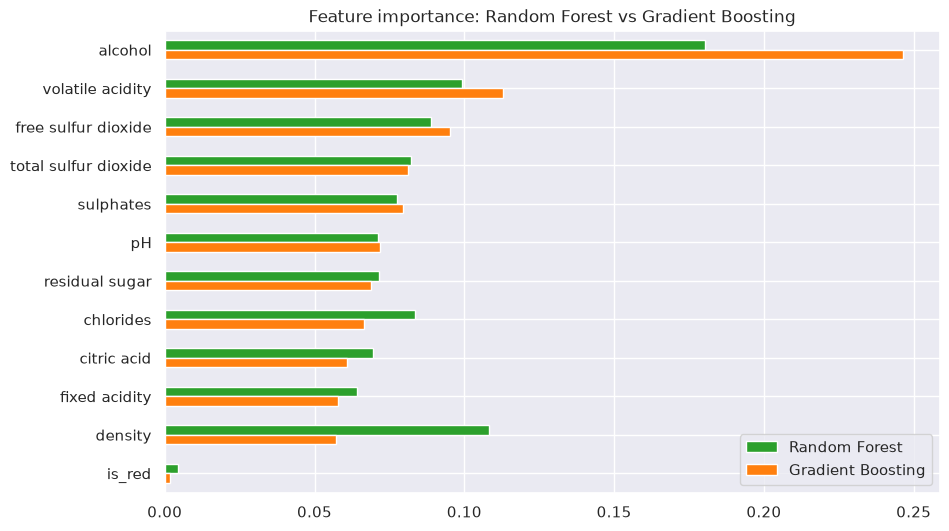

,alcohol,volatile acidity,free sulfur dioxide,total sulfur dioxide,sulphates,pH,residual sugar,chlorides,citric acid,fixed acidity,density,is_red
Random Forest,0.180,0.099,0.089,0.082,0.078,0.071,0.071,0.083,0.069,0.064,0.108,0.005
Gradient Boosting,0.246,0.113,0.095,0.081,0.080,0.072,0.069,0.066,0.061,0.058,0.057,0.002


In [41]:
gb_importance = pd.Series(gb.feature_importances_, index=FEATURES)
importance = pd.DataFrame({"Random Forest": rf_importance, "Gradient Boosting": gb_importance})
importance = importance.sort_values("Gradient Boosting", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
importance.plot.barh(ax=ax, color=["tab:green", "tab:orange"])
ax.invert_yaxis()
ax.set_title("Feature importance: Random Forest vs Gradient Boosting")
plt.show()
importance.round(3).T

**Вывод.**
- Общее: `alcohol` — первый с отрывом, `volatile acidity` — в тройке, `is_red` ≈ 0, остальные 0.06–0.10.
- **Различие — `density`: 2-я у леса (0.11), 11-я у бустинга (0.06)**, зато у бустинга больше `alcohol` (0.25 против 0.18). Бустинг в каждом разбиении выбирает лучший признак из всех — почти всегда `alcohol`, и коррелированная с ним `density` уже мало добавляет. В лесу в разбиении доступна треть признаков, и без `alcohol` его «заменяет» `density`. Сумма `alcohol` + `density` у моделей близка (0.29 и 0.30): модели по-разному делят одну и ту же информацию.

## 6. Честное сравнение моделей

Одинаковые условия: одни и те же train (4256) и test (1064), одни и те же признаки и метрики, гиперпараметры подобраны только по CV на train с одинаковыми фолдами.

In [29]:
final = pd.DataFrame(results).T[["RMSE test", "MAE test"]]
final.columns = ["RMSE", "MAE"]
final["улучшение RMSE к baseline, %"] = (1 - final["RMSE"] / final.loc["Baseline", "RMSE"]) * 100
final.round(4)

,RMSE,MAE,"улучшение RMSE к baseline, %"
Baseline,0.8801,0.6948,0.0000
Linear Regression,0.7292,0.5660,17.1412
Random Forest,0.6798,0.5256,22.7581
Gradient Boosting,0.6835,0.5279,22.3350


**Baseline превзошли все модели; порог RMSE < 0.70 прошли только ансамбли. Лучшая на тесте — Random Forest (RMSE 0.680, MAE 0.526);** на CV лес и бустинг равны (0.686).

Причины различий:
1. **Baseline → Linear Regression (−17%).** Модель использует монотонные связи из EDA (больше `alcohol` — выше оценка, больше `volatile acidity` — ниже).
2. **Linear Regression → деревья (ещё −6%).** Линейная модель недообучена (train ≈ test). Связи в данных нелинейны (у оценок 3–4 спирта больше, чем у 5) и зависят от типа вина (`citric acid`, `sulphates` важны только у красных), есть экстремальные значения признаков. Деревья строят кусочно-постоянную функцию и сами находят взаимодействия.
3. **Random Forest ≈ Gradient Boosting.** Разница в пределах шума (на CV чуть лучше бустинг, на тесте — лес). Целевая переменная шумная (субъективные оценки), данных немного — усреднение леса здесь не хуже последовательного исправления ошибок бустингом.

RMSE / MAE ≈ 1.27 у baseline и ≈ 1.29–1.30 у моделей: доля крупных промахов не уменьшилась — они сосредоточены на редких оценках (раздел 8).

## 7. Feature importance

Сравним важность признаков по всем источникам, нормировав каждый на сумму 1: |корреляция| (EDA), |вес| линейной регрессии на стандартизованных признаках, `feature_importances_` леса и бустинга.

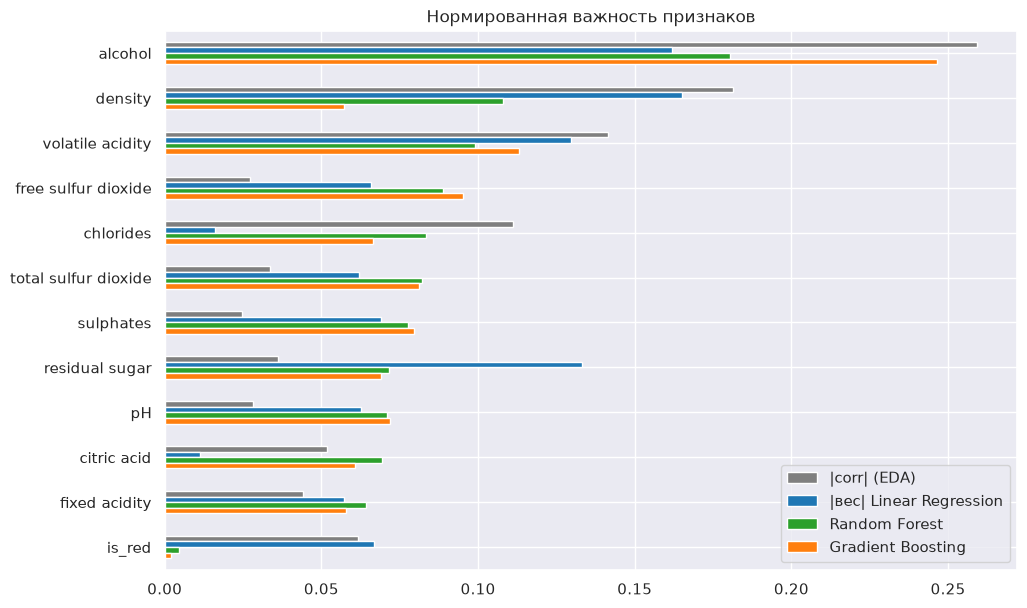

,|corr| (EDA),|вес| Linear Regression,Random Forest,Gradient Boosting,средний ранг
alcohol,1,2,1,1,1.25
volatile acidity,3,4,3,2,3.00
density,2,1,2,11,4.00
free sulfur dioxide,11,7,4,3,6.25
residual sugar,8,3,8,7,6.50
chlorides,4,11,5,8,7.00
total sulfur dioxide,9,9,6,4,7.00
sulphates,12,5,7,5,7.25
pH,10,8,9,6,8.25
is_red,5,6,12,12,8.75


In [42]:
all_importance = pd.DataFrame({
    "|corr| (EDA)": X_train.corrwith(y_train).abs(),
    "|вес| Linear Regression": coefs["вес (стандартизованные)"].abs(),
    "Random Forest": rf_importance,
    "Gradient Boosting": gb_importance,
})
all_importance = (all_importance / all_importance.sum()).sort_values("Random Forest", ascending=False)

fig, ax = plt.subplots(figsize=(11, 7))
all_importance.plot.barh(ax=ax, color=["tab:gray", "tab:blue", "tab:green", "tab:orange"])
ax.invert_yaxis()
ax.set_title("Нормированная важность признаков")
plt.show()

all_ranks = all_importance.rank(ascending=False).astype(int)
all_ranks["средний ранг"] = all_ranks.mean(axis=1)
all_ranks.sort_values("средний ранг")

**Вывод.**
- **Наиболее важны `alcohol` (1-е место везде, кроме LR, где 2-е) и `volatile acidity` (в первой четвёрке везде).** Это согласуется с EDA и со смыслом: зрелость винограда и «уксусный» дефект.
- `density` важна везде, кроме бустинга: она конкурирует с коррелированным `alcohol`, и как они поделят важность, зависит от алгоритма.
- Порядок остальных признаков зависит от модели. Корреляция видит только линейную связь одного признака, а модели используют признаки совместно и нелинейно: `free sulfur dioxide` по корреляции 11-й, а у леса и бустинга — 4-й и 3-й (вина с экстремальным свободным SO₂ в EDA получили 3–4).

**Можно ли по feature importance утверждать, что признак — причина изменения качества? Нет.** Важность показывает, насколько модель полагается на признак для прогноза в этих данных, — статистическую связь, а не причинную:
1. Данные наблюдательные, а не эксперимент «меняем один признак при прочих равных». Связь может идти через общую причину: спелый виноград даёт и больше спирта, и лучший вкус — добавив спирт в вино, его не улучшить.
2. Модель берёт любой полезный для прогноза признак, даже следствие других: `density` важна, хотя это лишь физическое следствие спирта и сахара.
3. Важность зависит от модели и набора признаков (`density`: 2-я у леса, 11-я у бустинга) — у причинного эффекта такой зависимости быть не может.
4. Важность деревьев не показывает даже направление эффекта.

Feature importance объясняет, на что опирается модель, и подсказывает гипотезы, но проверить причинность можно только экспериментом.

## 8. Анализ ошибок лучшей модели (Random Forest)

### 8.1 Распределение ошибок

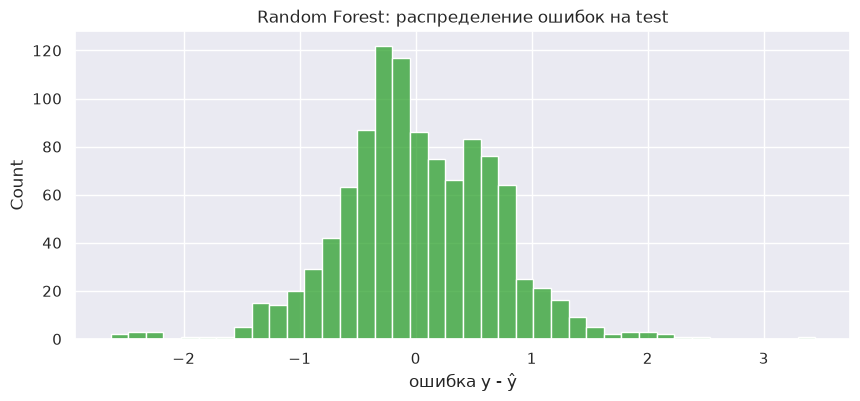

count    1064.000
mean        0.022
std         0.680
min        -2.630
25%        -0.387
50%        -0.038
75%         0.494
max         3.443
Name: quality, dtype: float64
|ошибка| < 0.5: 56.2%,  > 1: 11.9%,  > 1.5: 3.0%


In [30]:
errors = y_test - y_pred_rf

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(errors, bins=40, ax=ax, color="tab:green")
ax.set_xlabel("ошибка y - ŷ")
ax.set_title("Random Forest: распределение ошибок на test")
plt.show()

print(errors.describe().round(3))
print(f"|ошибка| < 0.5: {(errors.abs() < 0.5).mean():.1%},  > 1: {(errors.abs() > 1).mean():.1%},  "
      f"> 1.5: {(errors.abs() > 1.5).mean():.1%}")

**Вывод.** Средняя ошибка ≈ 0 — в целом модель не смещена ни вверх, ни вниз. 56% прогнозов ошибаются меньше чем на 0.5 балла, но у 12% ошибка больше 1 балла, у 3% — больше 1.5 (максимум 3.4). Эти редкие крупные ошибки и делают RMSE (0.68) заметно больше MAE (0.53).

### 8.2 Истинные и предсказанные значения по классам

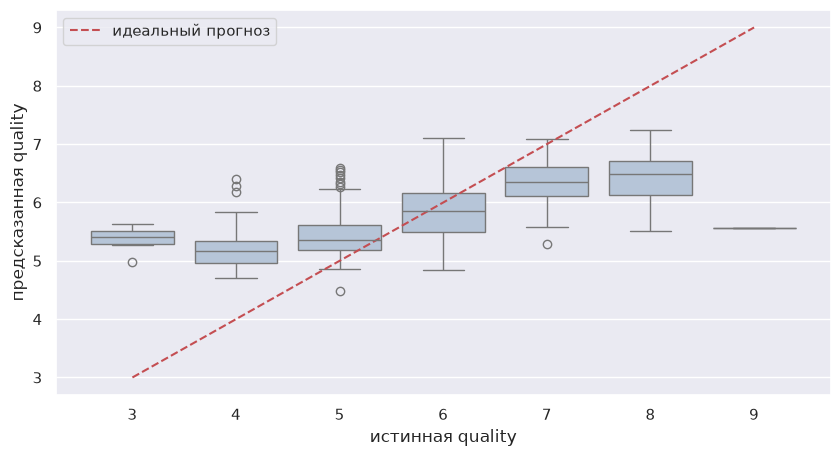

,объектов,средний_прогноз,средняя_ошибка,MAE,RMSE
y,,,,,
3,6,5.368,-2.368,2.368,2.377
4,41,5.230,-1.230,1.230,1.288
5,350,5.426,-0.426,0.433,0.538
6,465,5.841,0.159,0.386,0.467
7,171,6.335,0.665,0.666,0.754
8,30,6.450,1.550,1.550,1.612
9,1,5.557,3.443,3.443,3.443


In [32]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x=y_test, y=y_pred_rf, ax=ax, color="lightsteelblue")
ax.plot(range(7), range(3, 10), "r--", label="идеальный прогноз")
ax.set_xlabel("истинная quality")
ax.set_ylabel("предсказанная quality")
ax.legend()
plt.show()

by_class = pd.DataFrame({"y": y_test, "pred": y_pred_rf, "err": errors}).groupby("y").agg(
    объектов=("err", "size"),
    средний_прогноз=("pred", "mean"),
    средняя_ошибка=("err", "mean"),
    MAE=("err", lambda e: e.abs().mean()),
    RMSE=("err", lambda e: np.sqrt((e ** 2).mean())),
)
by_class.round(3)

In [33]:
pd.crosstab(y_test, np.round(y_pred_rf).astype(int), rownames=["истинная"], colnames=["округлённый прогноз"])

округлённый прогноз,4,5,6,7
истинная,,,,
3,0,4,2,0
4,0,35,6,0
5,1,232,114,3
6,0,121,307,37
7,0,1,110,60
8,0,0,15,15
9,0,0,1,0


**Вывод.** Модель работает **неодинаково** для разных оценок:
- На частых оценках 5 и 6 (77% теста) MAE ≈ 0.4.
- К краям ошибка растёт: для 4 и 7 MAE 1.2 и 0.7, для 3 и 8 — 2.4 и 1.6. Ошибка систематическая: оценки 3–4 завышаются, 7–8 занижаются.
- Прогнозы **сжаты к середине**: средний прогноз для оценки 3 — 5.4, для 8 — 6.5. Округлённый прогноз ни разу не равен 3, 8 или 9 — крайние оценки модель не предсказывает вообще, а 7 угадывает лишь в трети случаев.

### 8.3 Объекты с наибольшими ошибками

In [43]:
key_features = ["alcohol", "volatile acidity", "free sulfur dioxide", "total sulfur dioxide",
                "residual sugar", "is_red"]

worst = pd.DataFrame({"y": y_test, "pred": y_pred_rf, "err": errors}).join(X_test[key_features])
worst = worst.loc[worst["err"].abs().sort_values(ascending=False).index].head(10)
worst.round(3)

,y,pred,err,alcohol,volatile acidity,free sulfur dioxide,total sulfur dioxide,residual sugar,is_red
2012,9,5.557,3.443,10.4,0.270,28.0,124.0,10.60,0
1982,3,5.630,-2.630,12.6,0.390,5.0,19.0,4.60,0
1571,3,5.533,-2.533,9.8,0.260,41.0,197.0,16.20,0
2549,8,5.517,2.483,10.5,0.220,12.0,90.0,6.80,0
2783,3,5.417,-2.417,9.4,0.250,118.5,216.0,1.55,0
4984,4,6.407,-2.407,11.5,0.260,75.0,129.0,2.60,0
1165,3,5.383,-2.383,9.8,0.815,16.0,29.0,1.20,1
3881,8,5.700,2.300,12.5,0.530,6.0,76.0,6.10,0
4158,4,6.287,-2.287,12.9,0.640,18.0,76.0,1.20,0
1245,3,5.267,-2.267,9.7,0.980,20.0,49.0,2.10,1


In [35]:
X_train[key_features[:-1]].groupby([X_train["is_red"], y_train]).median().round(3)

alcohol  volatile acidity  free sulfur dioxide  \
is_red quality                                                   
0      3         10.500             0.260                 33.5   
       4         10.000             0.310                 18.0   
       5          9.600             0.290                 34.0   
       6         10.500             0.250                 33.0   
       7         11.500             0.252                 32.0   
       8         12.200             0.280                 34.0   
       9         12.600             0.310                 29.0   
1      3         10.075             0.818                  5.5   
       4         10.400             0.670                 11.0   
       5          9.600             0.580                 15.0   
       6         10.500             0.490                 15.0   
       7         11.500             0.370                 11.0   
       8         12.500             0.380                  8.0   

                total sulfur dioxide  residual sugar  
is_red quality                                        
0      3                       159.5            4.30  
       4                       119.0            2.30  
       5                       150.0            6.50  
       6                       131.0            4.80  
       7                       120.0            3.20  
       8                       116.0            3.80  
       9                       116.0            2.10  
1      3                        14.0            2.15  
       4                        30.0            2.15  
       5                        49.0            2.20  
       6                        36.0            2.20  
       7                        27.0            2.30  
       8                        24.0            2.00

**Разбор нескольких объектов** (сравнение с медианами train для того же типа вина):
- **Оценка 9, прогноз 5.6** (ошибка +3.4). По химии — обычное белое вино: `alcohol` 10.4, как у оценок 5–6 (у белых девяток медиана 12.6). В train всего 4 вина с оценкой 9, а по признакам это вино неотличимо от средних. Высокую оценку, вероятно, определили свойства, которых нет в данных (аромат, сорт), или субъективность эксперта.
- **Оценка 3, прогноз 5.4, `free sulfur dioxide` = 118.5** — втрое-вчетверо выше медианы белых (~30). В EDA вина с экстремальным свободным SO₂ получали 3–4: избыток SO₂ — дефект. Но таких вин в train единицы, и в листьях деревьев они усредняются с обычными винами — прогноз снижается недостаточно.
- **Оценка 3, прогноз 5.3 (красное), `volatile acidity` = 0.98** — выше даже медианы красных троек (0.82), у красных пятёрок 0.58. Модель понизила прогноз (ниже среднего 5.8), но до 3 не дошла: крайних примеров мало.
- **Оценка 4, прогноз 6.3 (белое): `alcohol` 12.9 и `volatile acidity` 0.64.** Признаки противоречат друг другу: высокий спирт тянет прогноз вверх, летучая кислотность, вдвое выше типичной для белых (~0.3), — вниз. В train крепкие вина чаще хорошие, и модель пошла за этим сигналом.

**Почему редкие оценки предсказываются хуже.**
1. **Мало примеров**: в train 24 вина с оценкой 3, 118 — с 8 и 4 — с 9 против 1858 с оценкой 6. Их закономерности модель выучить не может.
2. **MSE поощряет осторожность**: при неуверенности выгоднее прогноз ближе к среднему — ошибки на частых классах в сумме весят больше, чем на редких.
3. **Устройство леса**: прогноз листа — среднее его объектов, прогноз леса — среднее деревьев. Редкое вино почти всегда попадает в листья вместе с типичными, и двойное усреднение тянет прогноз к 5–6.
4. **Шум в оценках**: часть крайних вин по химии не отличается от средних (пример с оценкой 9) — такие ошибки на этих признаках не исправит никакая модель.

## 9. Заключение

- **Данные:** оценки сосредоточены на 5–6; главные признаки — `alcohol` (+) и `volatile acidity` (−); связи нелинейны и зависят от типа вина; `density` почти определяется `alcohol` и `residual sugar`; 18% дубликатов удалены до разбиения.
- **Эксперимент:** стратифицированный train/test 80/20 с фиксированным `random_state`; параметры подобраны только по 5-fold CV на train; тест использован один раз.
- **Результаты (test RMSE):** Baseline 0.880 → Linear Regression 0.729 → Gradient Boosting 0.684 → **Random Forest 0.680 (MAE 0.526)**. Порог 0.70 прошли ансамбли деревьев: они учитывают нелинейности и взаимодействия, недоступные линейной модели. Лес и бустинг равны в пределах шума.
- **Важность признаков:** все модели согласны насчёт `alcohol` и `volatile acidity`; деление важности между коррелированными `density` и `alcohol` зависит от алгоритма. Причинность по важности утверждать нельзя.
- **Ошибки:** на частых оценках 5–6 MAE ≈ 0.4, но прогноз систематически сжат к середине, и крайние оценки 3, 8, 9 модель не предсказывает: их мало в данных, а усреднение в лесу тянет прогноз к среднему.